# Retail Store Sales Analysis

## Step 1: Data Collection and Exploration

First I'll load the data and take a look at how it's laid out.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("retail_store_sales.csv")
df.head(10)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
6,TXN_3652209,CUST_07,Food,Item_1_FOOD,5.0,8.0,40.0,Credit Card,In-store,2023-06-10,True
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
8,TXN_9728486,CUST_23,Furniture,Item_16_FUR,27.5,1.0,27.5,Credit Card,In-store,2023-04-26,False
9,TXN_2722661,CUST_25,Butchers,Item_22_BUT,36.5,3.0,109.5,Cash,Online,2024-03-14,False


Now the structure: how many rows and columns there are, and what data type each column has.

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print()
df.info()

Rows: 12575
Columns: 11

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.9+ MB


The dataset has 12,575 rows and 11 columns. A few types look off. Transaction Date is a string instead of a date, Quantity is a float, and Discount Applied is an object column. I'll deal with these in the cleaning step.

Next, summary statistics to get a feel for the distributions.

In [4]:
df.describe(include="object")

C:\Users\lenovo\AppData\Local\Temp\ipykernel_19020\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Transaction ID,Customer ID,Category,Item,Payment Method,Location,Transaction Date,Discount Applied
count,12575,12575,12575,11362,12575,12575,12575,8376
unique,12575,25,8,200,3,2,1114,2
top,TXN_6867343,CUST_05,Furniture,Item_2_BEV,Cash,Online,2022-05-30,True
freq,1,544,1591,126,4310,6354,26,4219


Price and Quantity both stay within a small range (5 to 41 and 1 to 10), so nothing looks strange there. Total Spent goes up to 410, which is exactly 41 × 10, so that matches the other two columns.

Now I'll check for problems, starting with missing values.

In [5]:
missing = df.isna().sum()
pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df) * 100).round(2)
})

,missing,percent
Transaction ID,0,0.00
Customer ID,0,0.00
Category,0,0.00
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80
Payment Method,0,0.00
Location,0,0.00
Transaction Date,0,0.00


Item, Price Per Unit, Quantity, Total Spent and Discount Applied all have missing values. Discount Applied has the most, at about a third of the rows. The other columns are complete.

Next, outliers. I'll use the IQR rule on the three numeric columns.

In [6]:
for col in ["Price Per Unit", "Quantity", "Total Spent"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n} outliers (bounds {lower:.1f} to {upper:.1f})")

Price Per Unit: 0 outliers (bounds -15.2 to 62.8)
Quantity: 0 outliers (bounds -4.5 to 15.5)
Total Spent: 60 outliers (bounds -160.5 to 403.5)


Price and Quantity have no outliers. Total Spent has 60 flagged values, but they're just large purchases (a high price times a high quantity), and none go beyond the maximum possible value of 410. So they're real values, not errors.

Last, I'll check for inconsistent data: whether Total Spent matches Price × Quantity, and whether there are duplicates or bad values.

In [7]:
# Total Spent vs Price x Quantity
complete = df.dropna(subset=["Price Per Unit", "Quantity", "Total Spent"])
matches = np.isclose(complete["Price Per Unit"] * complete["Quantity"], complete["Total Spent"])
print("Rows where Total = Price x Quantity:", matches.sum(), "of", len(complete))

# Duplicates
print("Duplicate Transaction IDs:", df["Transaction ID"].duplicated().sum())

# Dates that can't be parsed
print("Invalid dates:", pd.to_datetime(df["Transaction Date"], errors="coerce").isna().sum())

# Zero or negative values
print("Zero/negative values:", (df[["Price Per Unit", "Quantity", "Total Spent"]] <= 0).sum().sum())

Rows where Total = Price x Quantity: 11362 of 11362
Duplicate Transaction IDs: 0
Invalid dates: 0
Zero/negative values: 0


Everything checks out here. Total Spent equals Price × Quantity in every complete row, there are no duplicate transactions, all dates are valid, and there are no zero or negative values.

So the main problem with this dataset is the missing values, plus the data types that need fixing.

## Step 2: Data Cleaning and Transformation

### Handling Missing Values

Here's how I'll handle each column with missing data:

- **Price Per Unit:** the Total Spent and Quantity are there in these rows, so I can calculate the price directly instead of guessing.
- **Item:** each Category and Price combination belongs to exactly one item, so once the price is back I can look the item up.
- **Quantity and Total Spent:** these are missing together and can't be calculated from anything else. Imputing them would mean inventing sales, so I'll remove those rows. It's only about 5% of the data.
- **Discount Applied:** a third of this column is missing and I can't recover it, so I'll keep those rows and label them "Unknown" rather than guess.

In [8]:
df_clean = df.copy()

# 1. Recover missing prices from Total Spent / Quantity
df_clean["Price Per Unit"] = df_clean["Price Per Unit"].fillna(
    df_clean["Total Spent"] / df_clean["Quantity"]
)

# 2. Recover missing items using the Category + Price combination
lookup = (df_clean.dropna(subset=["Item"])
          [["Category", "Price Per Unit", "Item"]]
          .drop_duplicates(["Category", "Price Per Unit"])
          .rename(columns={"Item": "Item_lookup"}))

df_clean = df_clean.merge(lookup, on=["Category", "Price Per Unit"], how="left")
df_clean["Item"] = df_clean["Item"].fillna(df_clean["Item_lookup"])
df_clean = df_clean.drop(columns="Item_lookup")

# 3. Drop rows where Quantity and Total Spent are missing
df_clean = df_clean.dropna(subset=["Quantity", "Total Spent"])

# 4. Keep missing discount info as its own category
df_clean["Discount Applied"] = (df_clean["Discount Applied"]
                                .map({True: "True", False: "False"})
                                .fillna("Unknown"))

print("Rows before:", len(df), "| after:", len(df_clean))
print()
print(df_clean.isna().sum())

Rows before: 12575 | after: 11971

Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64


### Outlier Detection and Treatment

I'll use box plots to look at the three numeric columns.

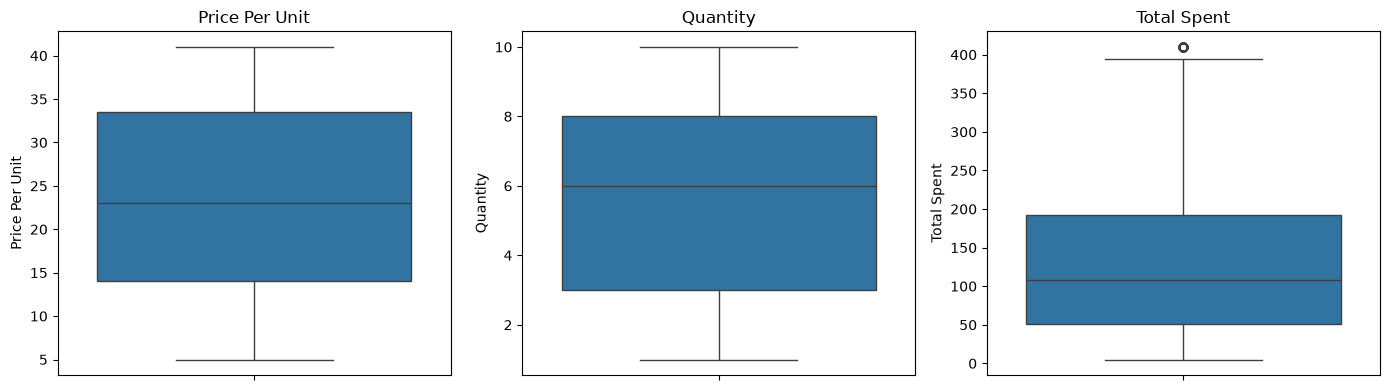

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Price Per Unit", "Quantity", "Total Spent"]):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [10]:
for col in ["Price Per Unit", "Quantity", "Total Spent"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"{col}: {n} outliers (upper bound {upper:.1f}, max value {df_clean[col].max()})")

Price Per Unit: 0 outliers (upper bound 62.8, max value 41.0)
Quantity: 0 outliers (upper bound 15.5, max value 10.0)
Total Spent: 60 outliers (upper bound 403.5, max value 410.0)


Price and Quantity have no outliers. Total Spent shows some points above the whiskers, but they're simply big purchases, and the largest (410) is exactly the highest price times the highest quantity. These are real transactions, not errors, and removing them would throw away the best sales, so I'm keeping them.

### Data Transformation

First, fixing the data types I noticed earlier.

In [11]:
df_clean["Transaction Date"] = pd.to_datetime(df_clean["Transaction Date"])
df_clean["Quantity"] = df_clean["Quantity"].astype(int)

df_clean.dtypes

Transaction ID                 str
Customer ID                    str
Category                       str
Item                           str
Price Per Unit             float64
Quantity                     int64
Total Spent                float64
Payment Method                 str
Location                       str
Transaction Date    datetime64[us]
Discount Applied               str
dtype: object

Now some new features. The date can give me the year, month, quarter and day of the week, plus a weekend flag. I'll also split Total Spent into low, medium and high spend levels.

In [12]:
df_clean["Year"] = df_clean["Transaction Date"].dt.year
df_clean["Month"] = df_clean["Transaction Date"].dt.month
df_clean["Quarter"] = df_clean["Transaction Date"].dt.quarter
df_clean["Day of Week"] = df_clean["Transaction Date"].dt.day_name()
df_clean["Is Weekend"] = df_clean["Transaction Date"].dt.dayofweek >= 5

df_clean["Spend Level"] = pd.qcut(df_clean["Total Spent"], q=3,
                                  labels=["Low", "Medium", "High"])

df_clean[["Transaction Date", "Year", "Month", "Quarter",
          "Day of Week", "Is Weekend", "Total Spent", "Spend Level"]].head()

,Transaction Date,Year,Month,Quarter,Day of Week,Is Weekend,Total Spent,Spend Level
0,2024-04-08,2024,4,2,Monday,False,185.0,High
1,2023-07-23,2023,7,3,Sunday,True,261.0,High
2,2022-10-05,2022,10,4,Wednesday,False,43.0,Low
3,2022-05-07,2022,5,2,Saturday,True,247.5,High
4,2022-10-02,2022,10,4,Sunday,True,87.5,Medium


Next, encoding the categorical columns. Category, Payment Method, Location and Discount Applied have only a few values each, so one-hot encoding works well. Item and Customer ID have many values, so one-hot would create too many columns. I'll label encode those instead.

I'm doing this on a separate copy so the readable version of the data stays available for the analysis and charts later.

In [13]:
from sklearn.preprocessing import LabelEncoder

df_model = df_clean.copy()

# One-hot encoding for columns with few categories
df_model = pd.get_dummies(
    df_model,
    columns=["Category", "Payment Method", "Location", "Discount Applied"],
    drop_first=True
)

# Label encoding for columns with many categories
for col in ["Item", "Customer ID"]:
    df_model[col + " Encoded"] = LabelEncoder().fit_transform(df_model[col])

df_model.head()

,Transaction ID,Customer ID,Item,Price Per Unit,Quantity,Total Spent,Transaction Date,Year,Month,Quarter,...,Category_Furniture,Category_Milk Products,Category_Patisserie,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_Online,Discount Applied_True,Discount Applied_Unknown,Item Encoded,Customer ID Encoded
0,TXN_6867343,CUST_09,Item_10_PAT,18.5,10,185.0,2024-04-08,2024,4,2,...,False,False,True,False,True,True,True,False,7,8
1,TXN_3731986,CUST_22,Item_17_MILK,29.0,9,261.0,2023-07-23,2023,7,3,...,False,True,False,False,True,True,True,False,62,21
2,TXN_9303719,CUST_02,Item_12_BUT,21.5,2,43.0,2022-10-05,2022,10,4,...,False,False,False,True,False,True,False,False,17,1
3,TXN_9458126,CUST_06,Item_16_BEV,27.5,9,247.5,2022-05-07,2022,5,2,...,False,False,False,True,False,True,False,True,48,5
4,TXN_4575373,CUST_05,Item_6_FOOD,12.5,7,87.5,2022-10-02,2022,10,4,...,False,False,False,False,True,True,False,False,172,4


Finally, scaling. Price, Quantity and Total Spent are on very different scales (Quantity is at most 10 while Total Spent goes to 410), which would matter for distance-based or linear models. I'll standardize them into new columns and keep the originals.

In [14]:
from sklearn.preprocessing import StandardScaler

num_cols = ["Price Per Unit", "Quantity", "Total Spent"]
scaled = StandardScaler().fit_transform(df_model[num_cols])

for i, col in enumerate(num_cols):
    df_model[col + " Scaled"] = scaled[:, i]

df_model[[c + " Scaled" for c in num_cols]].describe().round(2)

,Price Per Unit Scaled,Quantity Scaled,Total Spent Scaled
count,11971.00,11971.00,11971.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.71,-1.59,-1.32
25%,-0.87,-0.89,-0.83
50%,-0.03,0.16,-0.22
75%,0.94,0.86,0.66
max,1.64,1.56,2.96


## Step 3: Exploratory Data Analysis (EDA)

Now that the data is clean, I'll explore it properly. I'm using `df_clean` from the last step, since it still has readable labels. I'm leaving out the partial month of January 2025 in the time trends, because it only has 18 days and would make the end of the series look like a drop.

### Descriptive Statistics

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

num_cols = ["Price Per Unit", "Quantity", "Total Spent"]
df_clean[num_cols].describe().round(2)

,Price Per Unit,Quantity,Total Spent
count,11971.00,11971.00,11971.00
mean,23.36,5.54,129.65
std,10.74,2.86,94.75
min,5.00,1.00,5.00
25%,14.00,3.00,51.00
50%,23.00,6.00,108.50
75%,33.50,8.00,192.00
max,41.00,10.00,410.00


In [16]:
cat_cols = ["Category", "Payment Method", "Location", "Discount Applied"]

for col in cat_cols:
    print(f"--- {col} ---")
    print(pd.DataFrame({
        "count": df_clean[col].value_counts(),
        "percent": (df_clean[col].value_counts(normalize=True) * 100).round(1)
    }))
    print()

--- Category ---
                                    count  percent
Category                                          
Furniture                            1525     12.7
Electric household essentials        1516     12.7
Milk Products                        1513     12.6
Food                                 1507     12.6
Butchers                             1496     12.5
Beverages                            1496     12.5
Computers and electric accessories   1477     12.3
Patisserie                           1441     12.0

--- Payment Method ---
                count  percent
Payment Method                
Cash             4103     34.3
Digital Wallet   3941     32.9
Credit Card      3927     32.8

--- Location ---
          count  percent
Location                
Online     6068     50.7
In-store   5903     49.3

--- Discount Applied ---
                  count  percent
Discount Applied                
True               4019     33.6
Unknown            3988     33.3
False             

In [17]:
# Total spend and average spend per transaction by category
df_clean.groupby("Category")["Total Spent"].agg(["sum", "mean", "count"]).round(1).sort_values("sum", ascending=False)

,sum,mean,count
Category,,,
Butchers,208118.0,139.1,1496
Electric household essentials,203813.5,134.4,1516
Beverages,197047.5,131.7,1496
Furniture,195310.0,128.1,1525
Food,194812.0,129.3,1507
Computers and electric accessories,190692.5,129.1,1477
Patisserie,182165.5,126.4,1441
Milk Products,180112.0,119.0,1513


### Distributions

First, how each of the numeric columns is distributed.

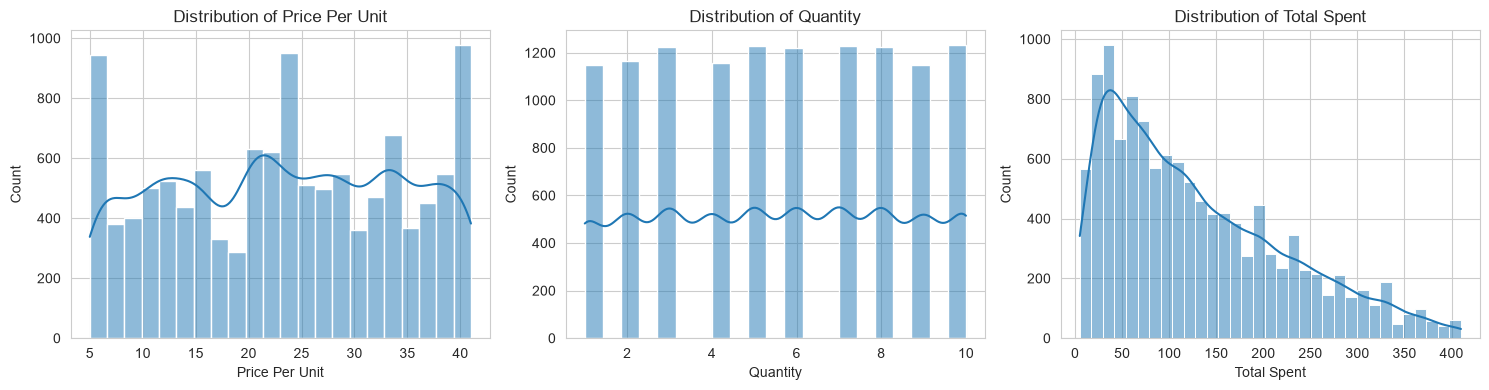

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

Price and Quantity are spread fairly evenly across their ranges, with no real peak. Total Spent is different: it bunches up at the low end and has a long tail to the right. That makes sense, since a big total needs both a high price and a high quantity.

Next, how the transactions are split across the categorical columns.

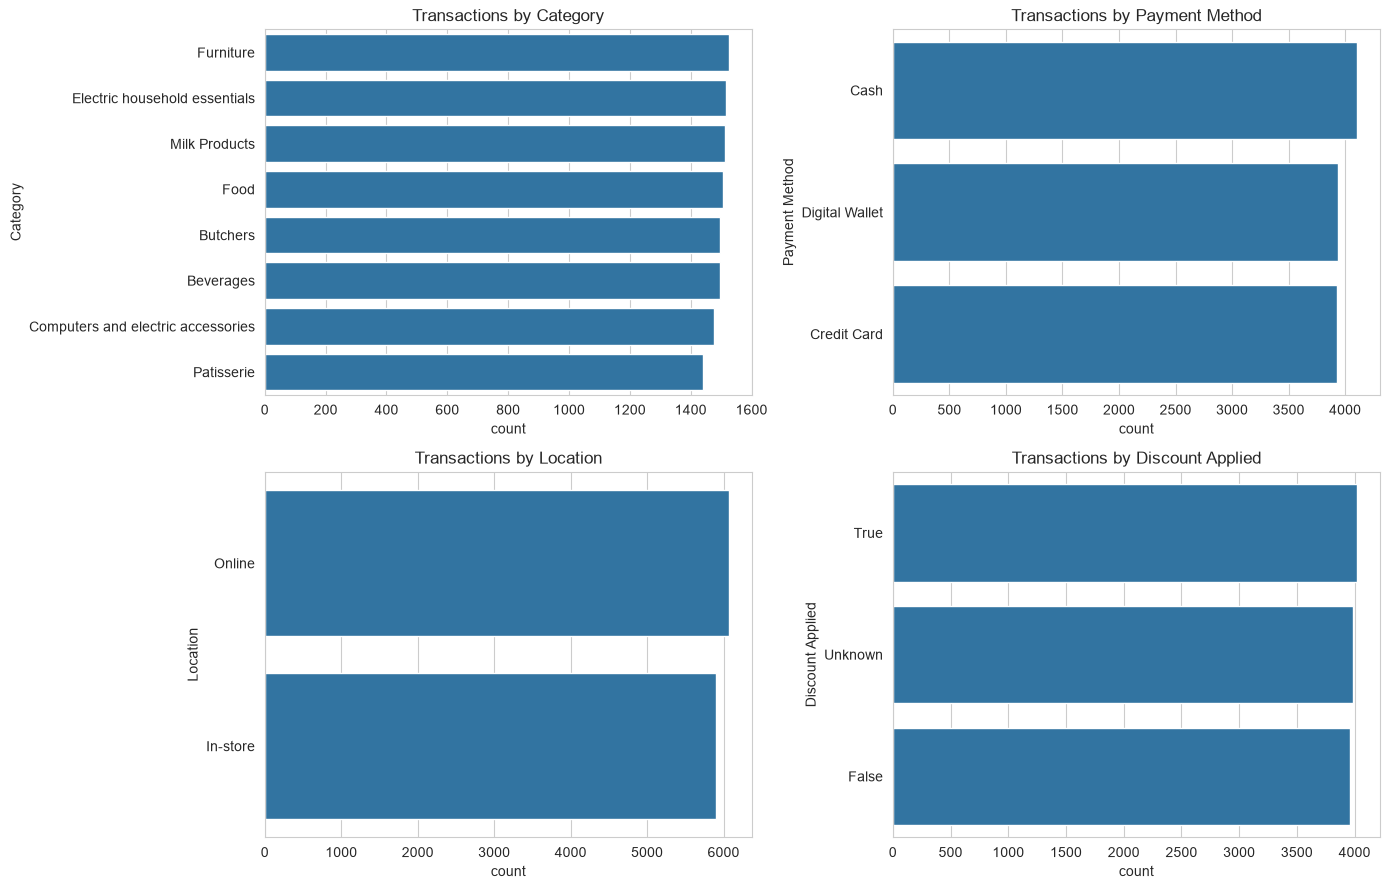

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cat_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, y=col, order=order, ax=ax)
    ax.set_title(f"Transactions by {col}")

plt.tight_layout()
plt.show()

The transaction counts are very balanced. Each category, payment method, and location accounts for a similar share of the sales, so no group is much bigger than the others.

### Relationships Between Variables

Here's how price and quantity each relate to the total spent.

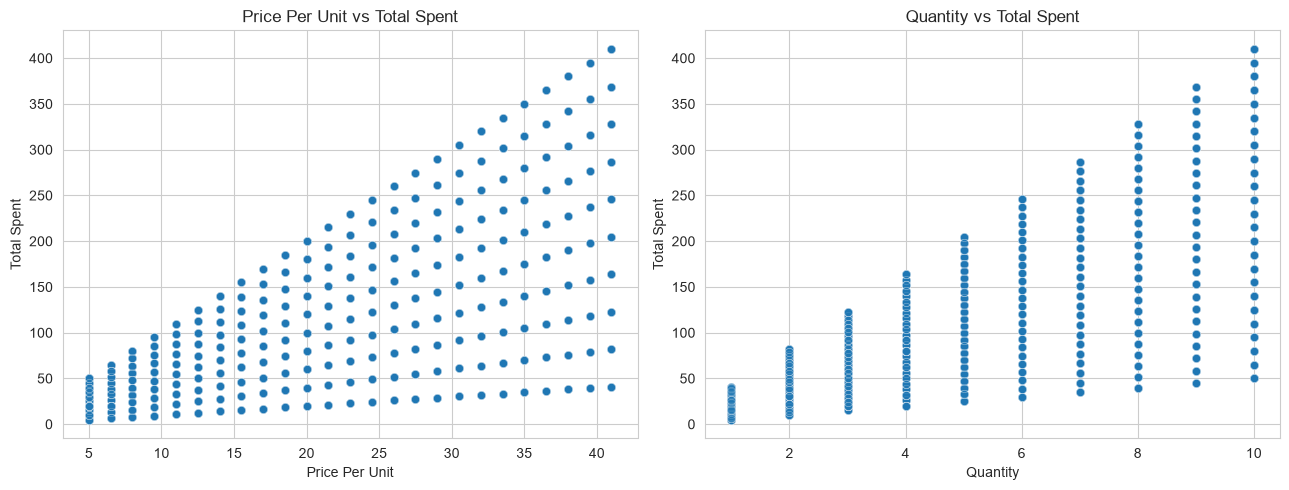

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df_clean, x="Price Per Unit", y="Total Spent", alpha=0.3, ax=axes[0])
axes[0].set_title("Price Per Unit vs Total Spent")

sns.scatterplot(data=df_clean, x="Quantity", y="Total Spent", alpha=0.3, ax=axes[1])
axes[1].set_title("Quantity vs Total Spent")

plt.tight_layout()
plt.show()

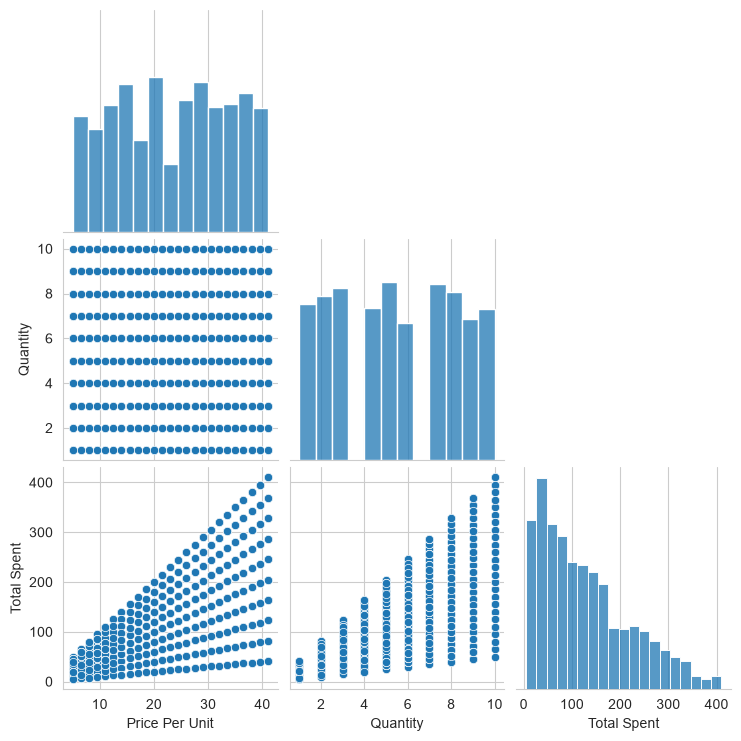

In [21]:
sns.pairplot(df_clean[num_cols].sample(2000, random_state=42), corner=True)
plt.show()

Both scatter plots show Total Spent rising with Price and Quantity. The fan shape is because the total is the two multiplied together. Price and Quantity look unrelated to each other, which the pair plot confirms.

Now how spending differs across the categories, locations, payment methods and discount groups.

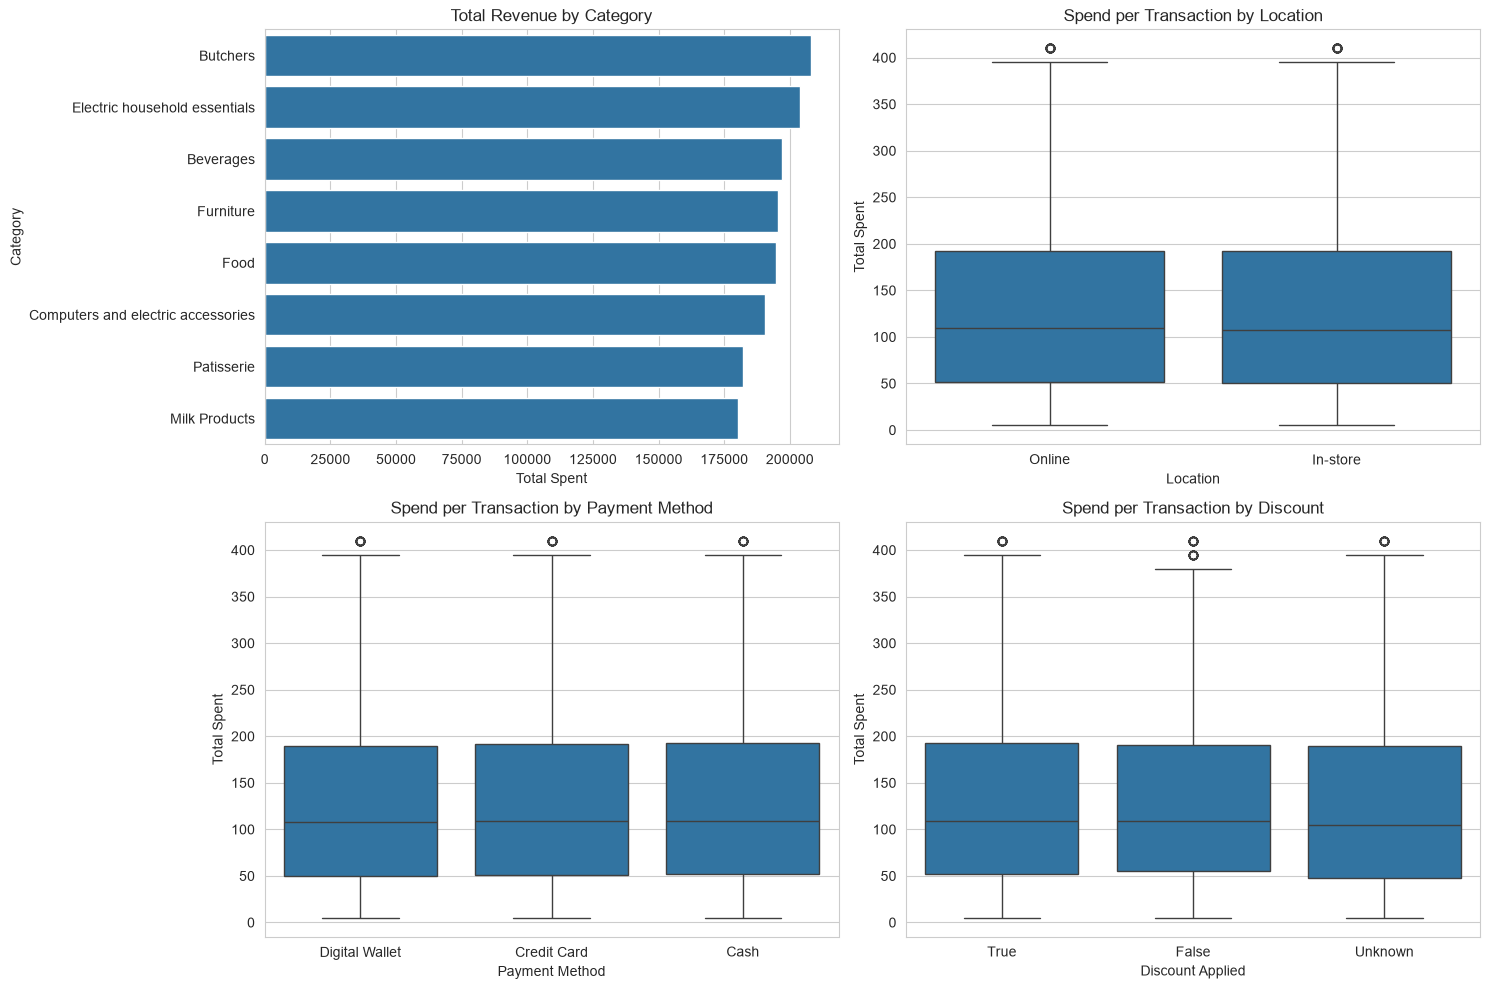

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

order = df_clean.groupby("Category")["Total Spent"].sum().sort_values(ascending=False).index
sns.barplot(data=df_clean, y="Category", x="Total Spent", estimator="sum",
            order=order, errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title("Total Revenue by Category")

sns.boxplot(data=df_clean, x="Location", y="Total Spent", ax=axes[0, 1])
axes[0, 1].set_title("Spend per Transaction by Location")

sns.boxplot(data=df_clean, x="Payment Method", y="Total Spent", ax=axes[1, 0])
axes[1, 0].set_title("Spend per Transaction by Payment Method")

sns.boxplot(data=df_clean, x="Discount Applied", y="Total Spent", ax=axes[1, 1])
axes[1, 1].set_title("Spend per Transaction by Discount")

plt.tight_layout()
plt.show()

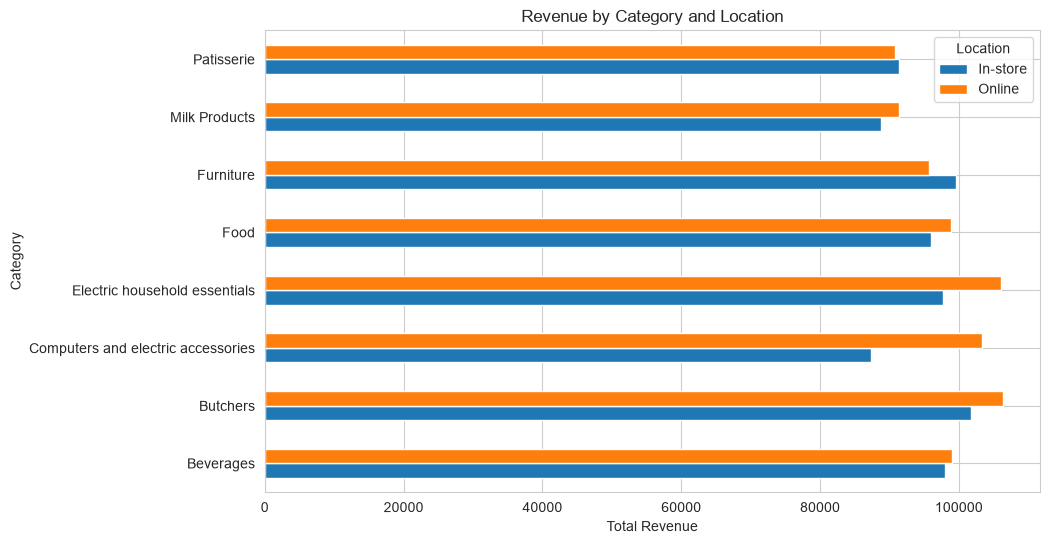

In [23]:
# Revenue by category and location
cat_loc = df_clean.pivot_table(index="Category", columns="Location",
                               values="Total Spent", aggfunc="sum")

cat_loc.plot(kind="barh", figsize=(10, 6))
plt.title("Revenue by Category and Location")
plt.xlabel("Total Revenue")
plt.show()

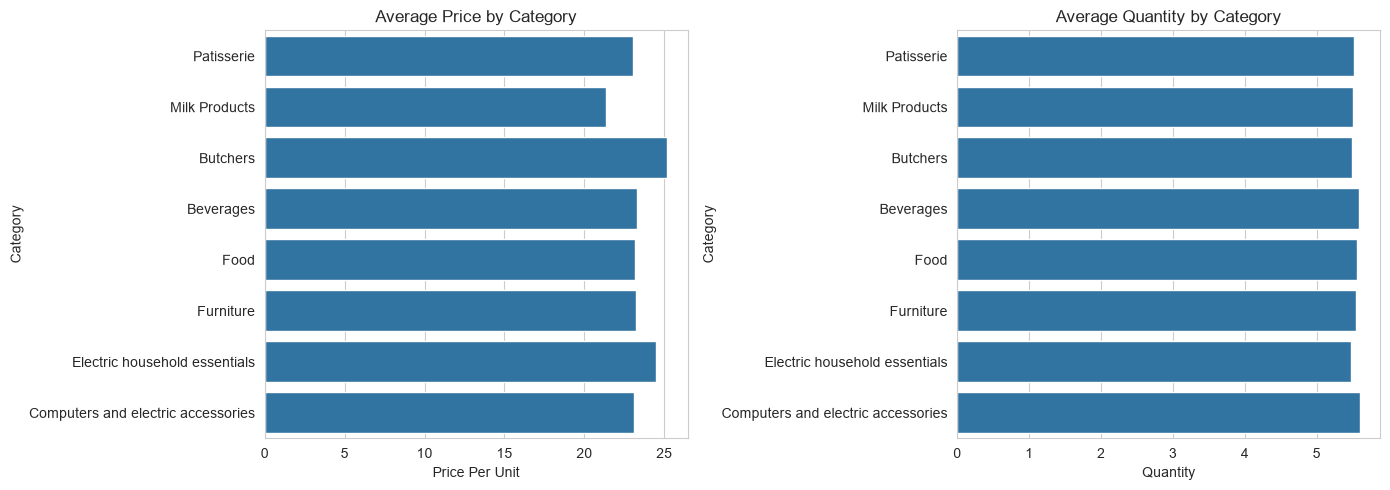

In [24]:
# Average price and quantity by category, to see what drives the revenue gap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_clean, y="Category", x="Price Per Unit", errorbar=None, ax=axes[0])
axes[0].set_title("Average Price by Category")

sns.barplot(data=df_clean, y="Category", x="Quantity", errorbar=None, ax=axes[1])
axes[1].set_title("Average Quantity by Category")

plt.tight_layout()
plt.show()

### Pie Charts: Share of Revenue

Three separate pie charts showing how total revenue splits across categories, payment methods, and locations.

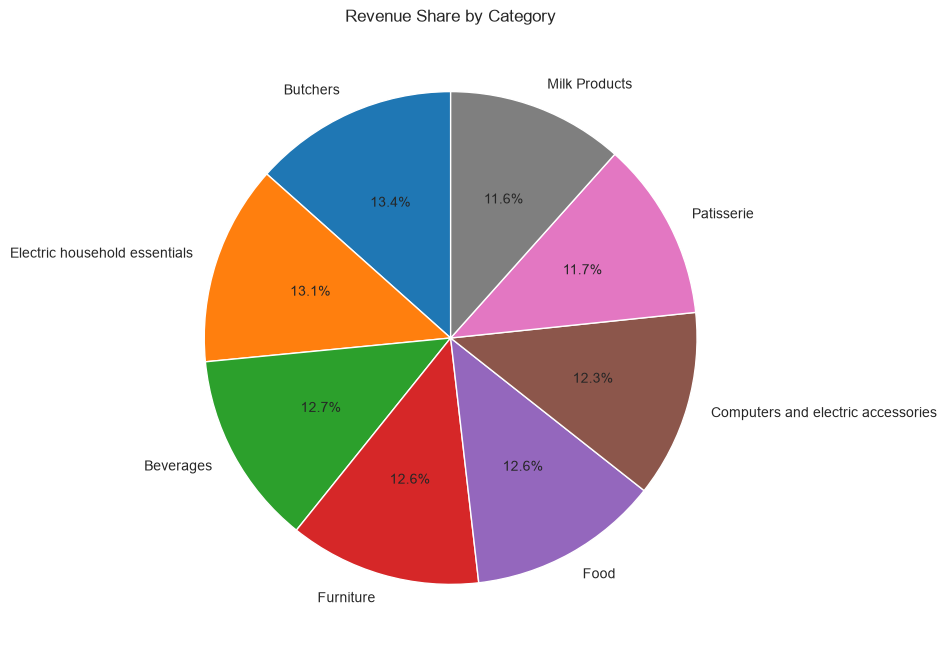

In [25]:

# Pie chart 1: revenue share by category
cat_rev = df_clean.groupby("Category")["Total Spent"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 8))
plt.pie(cat_rev, labels=cat_rev.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Category")
plt.show()


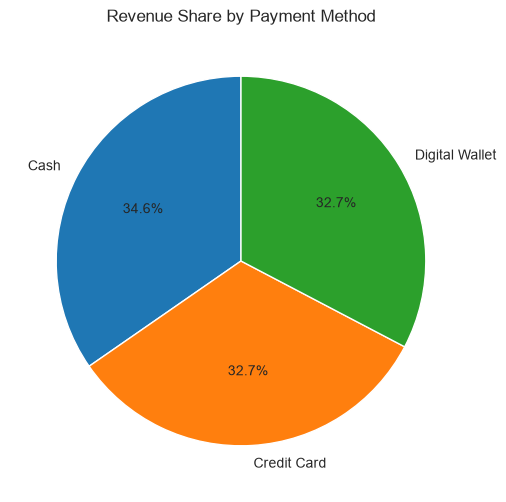

In [26]:
# Pie chart 2: revenue share by payment method
pay_rev = df_clean.groupby("Payment Method")["Total Spent"].sum()

plt.figure(figsize=(6, 6))
plt.pie(pay_rev, labels=pay_rev.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Payment Method")
plt.show()

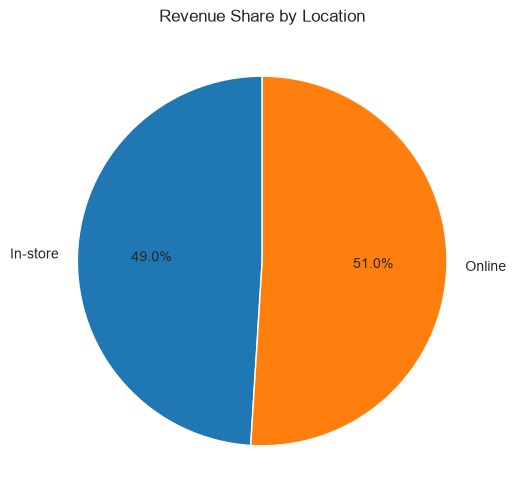

In [27]:
# Pie chart 3: revenue share by location
loc_rev = df_clean.groupby("Location")["Total Spent"].sum()

plt.figure(figsize=(6, 6))
plt.pie(loc_rev, labels=loc_rev.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Location")
plt.show()

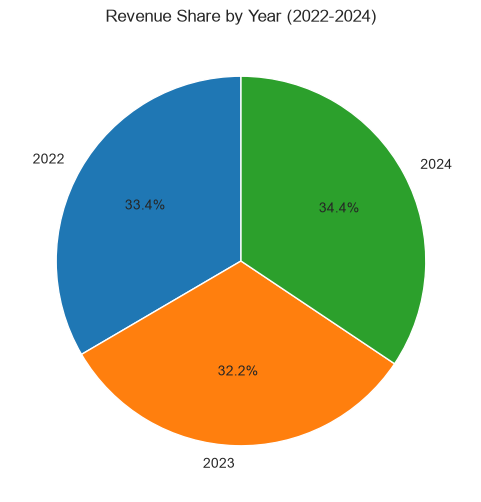

In [28]:
# Pie chart 6: revenue share by year (2025 excluded, it only has 18 days)
year_rev = (df_clean[df_clean["Transaction Date"] < "2025-01-01"]
            .groupby("Year")["Total Spent"].sum())

plt.figure(figsize=(6, 6))
plt.pie(year_rev, labels=year_rev.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share by Year (2022-2024)")
plt.show()

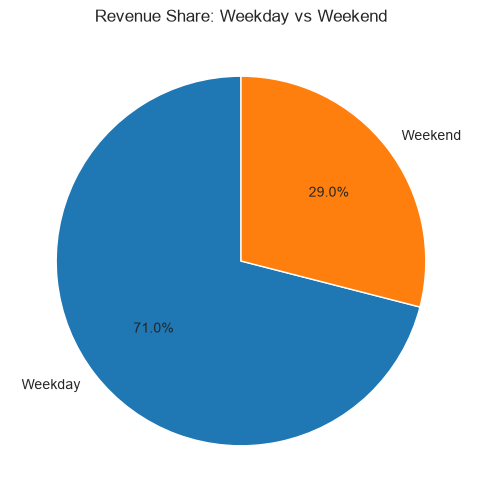

In [29]:
# Pie chart 7: revenue share, weekday vs weekend
wk_rev = df_clean.groupby("Is Weekend")["Total Spent"].sum()
wk_rev.index = wk_rev.index.map({False: "Weekday", True: "Weekend"})

plt.figure(figsize=(6, 6))
plt.pie(wk_rev, labels=wk_rev.index, autopct="%1.1f%%", startangle=90)
plt.title("Revenue Share: Weekday vs Weekend")
plt.show()

### Trends Over Time

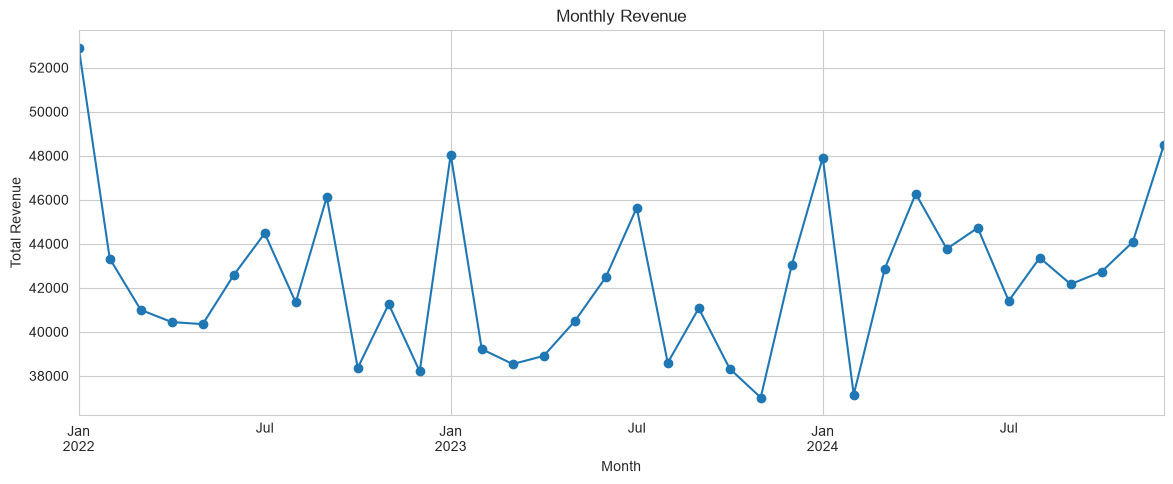

In [30]:
# Monthly revenue (excluding the partial month of January 2025)
trend = df_clean[df_clean["Transaction Date"] < "2025-01-01"].copy()
monthly = trend.groupby(trend["Transaction Date"].dt.to_period("M"))["Total Spent"].sum()

plt.figure(figsize=(14, 5))
monthly.plot(marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.show()

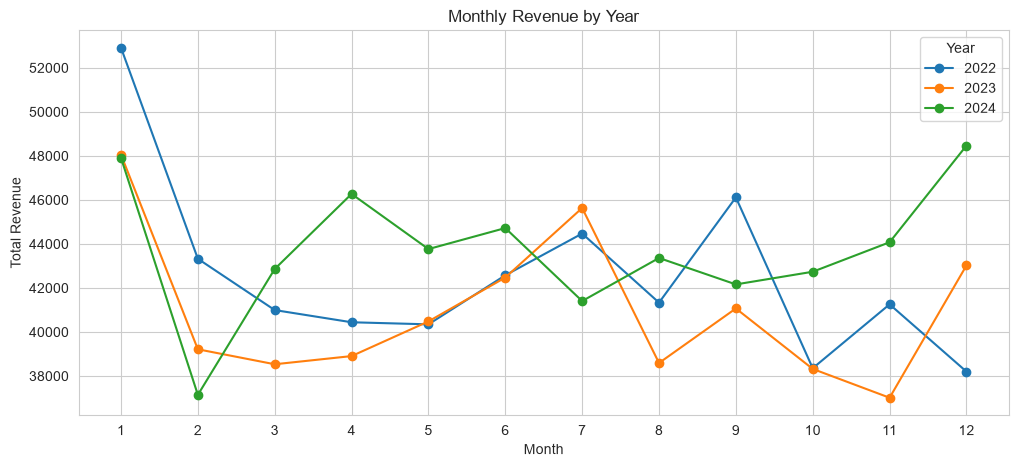

In [31]:
# Revenue by month of year, one line per year
month_year = trend.pivot_table(index="Month", columns="Year", values="Total Spent", aggfunc="sum")

month_year.plot(marker="o", figsize=(12, 5))
plt.title("Monthly Revenue by Year")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(range(1, 13))
plt.show()

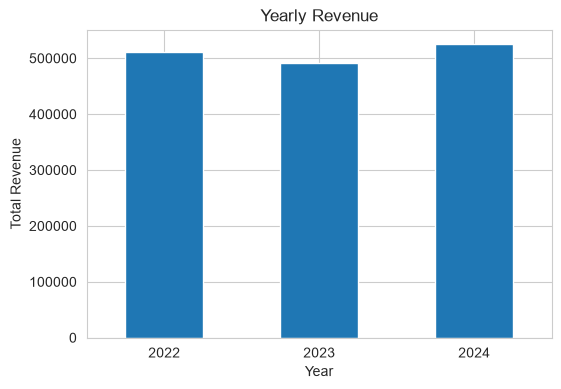

Year
2022    510329.5
2023    491312.0
2024    524881.0
Name: Total Spent, dtype: float64

In [32]:
# Yearly revenue (2025 left out, it only has 18 days)
yearly = trend.groupby("Year")["Total Spent"].sum()

yearly.plot(kind="bar", figsize=(6, 4))
plt.title("Yearly Revenue")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.show()

yearly

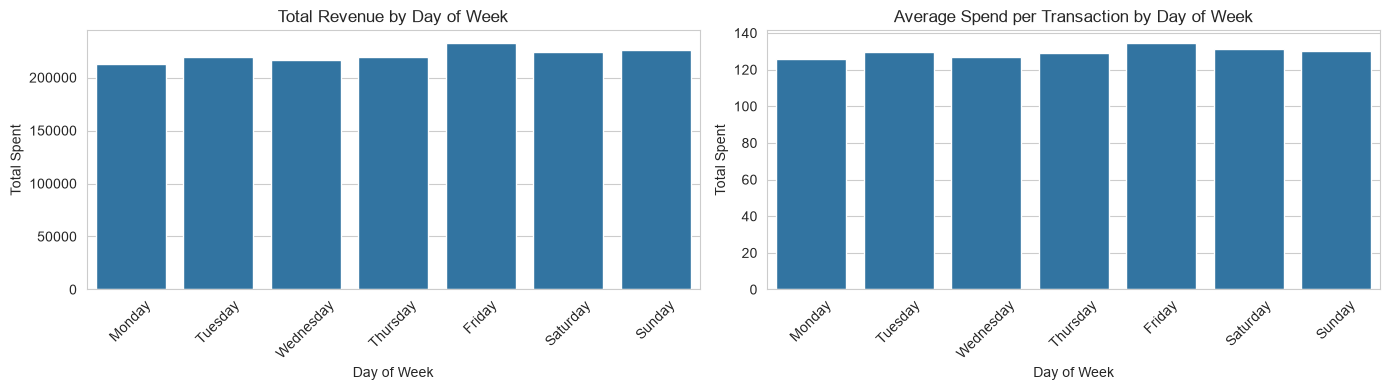

In [33]:
# Day of week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=df_clean, x="Day of Week", y="Total Spent", estimator="sum",
            order=day_order, errorbar=None, ax=axes[0])
axes[0].set_title("Total Revenue by Day of Week")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df_clean, x="Day of Week", y="Total Spent",
            order=day_order, errorbar=None, ax=axes[1])
axes[1].set_title("Average Spend per Transaction by Day of Week")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

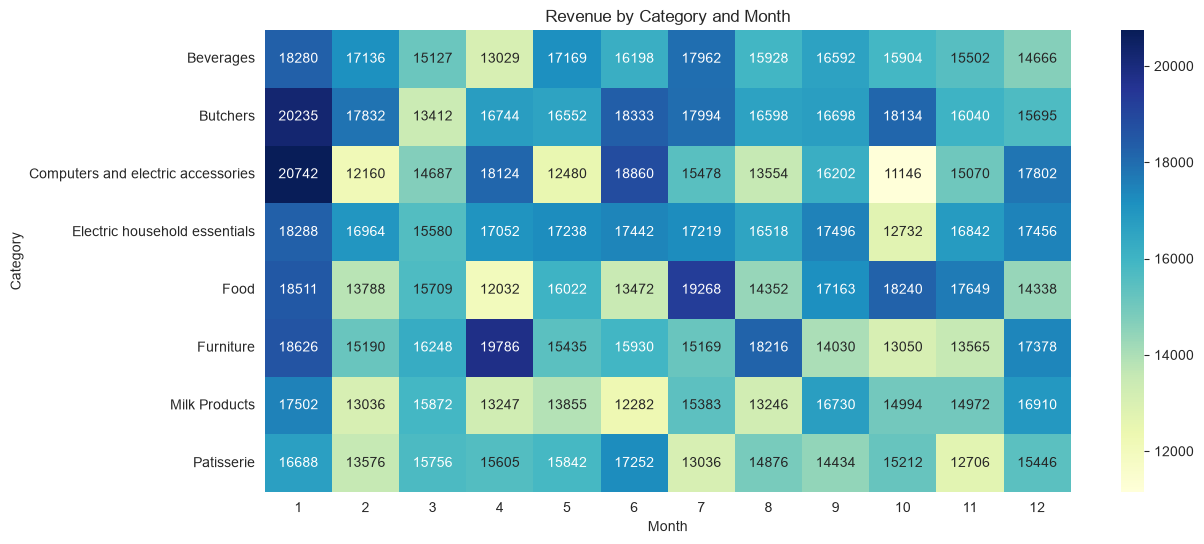

In [34]:
# Heatmap: revenue by category and month (shows which categories peak when)
cat_month = df_clean[df_clean["Year"] < 2025].pivot_table(
    index="Category", columns="Month", values="Total Spent", aggfunc="sum")

plt.figure(figsize=(13, 6))
sns.heatmap(cat_month, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Revenue by Category and Month")
plt.show()

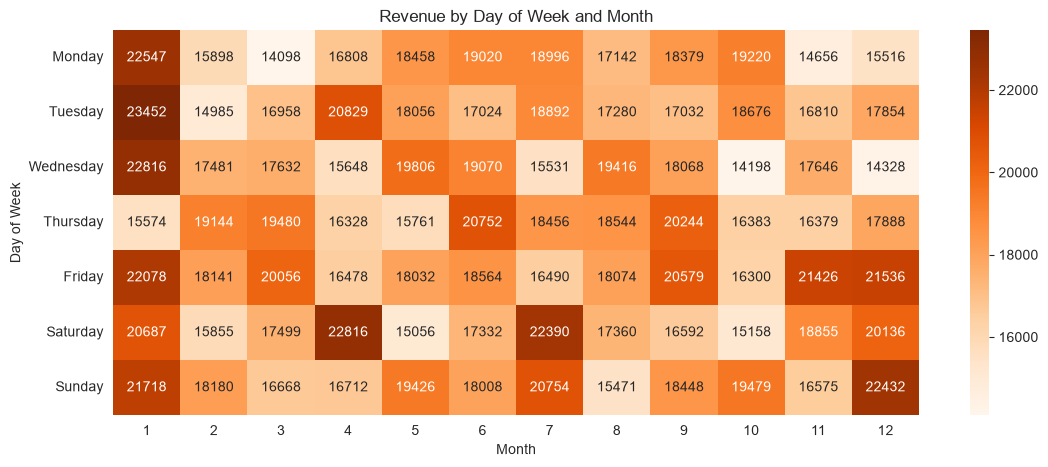

In [38]:
# Heatmap: revenue by day of week and month
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_month = df_clean[df_clean["Year"] < 2025].pivot_table(
    index="Day of Week", columns="Month", values="Total Spent", aggfunc="sum").loc[day_order]

plt.figure(figsize=(13, 5))
sns.heatmap(dow_month, annot=True, fmt=".0f", cmap="Oranges")
plt.title("Revenue by Day of Week and Month")
plt.show()

In [35]:
### Correlations

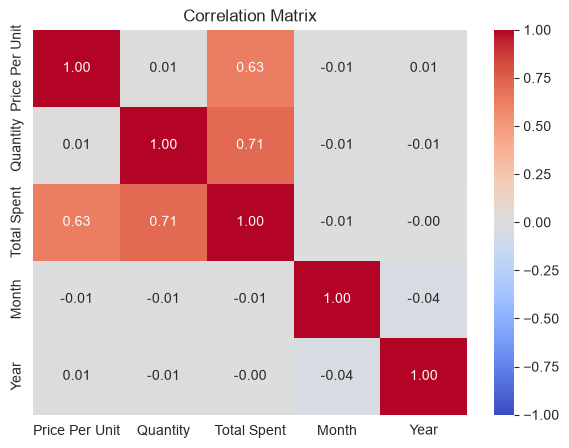

In [36]:
corr = df_clean[num_cols + ["Month", "Year"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

Total Spent is correlated with both Quantity (0.71) and Price (0.63), which is expected because it's calculated from them. Price and Quantity are almost uncorrelated with each other (0.01), so shoppers don't buy fewer units of the more expensive things.

### Which Differences Are Real?

Some of the groups look slightly different in the charts, so I'll test whether the differences in spend per transaction are bigger than random variation would produce.

In [37]:
from scipy import stats

# t-test for Location (2 groups)
online = df_clean.loc[df_clean["Location"] == "Online", "Total Spent"]
instore = df_clean.loc[df_clean["Location"] == "In-store", "Total Spent"]
print("Location (t-test) p-value:", round(stats.ttest_ind(online, instore).pvalue, 4))

# ANOVA for the groups with 3+ categories
for col in ["Category", "Payment Method", "Discount Applied"]:
    groups = [g["Total Spent"] for _, g in df_clean.groupby(col)]
    print(f"{col} (ANOVA) p-value:", round(stats.f_oneway(*groups).pvalue, 4))

Location (t-test) p-value: 0.3677
Category (ANOVA) p-value: 0.0
Payment Method (ANOVA) p-value: 0.4966
Discount Applied (ANOVA) p-value: 0.6263


### Key Insights

**1. Category is the only factor that clearly changes spending.** Butchers brings in the most revenue (about 208K) and Milk Products the least (about 180K), roughly 13% lower. The difference is statistically significant (p < 0.001). It comes from price, not from how much people buy: Butchers has the highest average price (25.2) and Milk Products the lowest (21.3), while average quantity is almost identical across every category (5.5 to 5.6 units).

**2. Location, payment method and discounts make no real difference.** Online sales bring in slightly more revenue than in-store, but the average spend per transaction is almost the same (130.4 vs 128.9), and the same goes for the three payment methods and the discount groups. None of these differences are statistically significant. Discounts in particular don't seem to be linked to bigger or smaller baskets.

**3. Online is stronger for some categories.** Computers and electric accessories makes about 103K online against about 87K in-store, and Electric household essentials and Butchers also lean online. I haven't tested this, so it's a lead to check rather than a conclusion.

**4. Revenue is steady over time, with a January bump.** Monthly revenue averages about 42K and stays between roughly 37K and 53K. Yearly revenue dipped about 4% from 2022 to 2023, then recovered about 7% in 2024 to its highest level. January stands out as the strongest month in the data (about 149K combined over the three full Januaries, against roughly 120K to 130K for most other months), and January 2022 was the single best month overall.

**5. Day of week has only small effects.** Friday has the highest revenue and average spend (134.6 per transaction), and Monday has the lowest average (125.6). The gaps are small, so I'd treat them as weak patterns.

**6. Customers are evenly spread.** Each of the 25 customers has spent between about 57K and 68K, so revenue doesn't depend on a few big accounts.

### Suggestions for Decision-Making and Further Analysis

- **Pricing is the main lever.** Since quantity is flat across categories, revenue differences come down to price, so price and range decisions will matter more than promotions.
- **Review the discounts.** They don't seem to lift spending, so it's worth checking what they cost before continuing them.
- **Look into January.** Finding out what drives the bump (new year purchases, promotions, stock) could help repeat it in other months.
- **Dig into the online vs in-store gap by category,** especially for Computers and electric accessories.
- **Caveats:** the data has only 25 customers and is very evenly distributed, so it may be synthetic. 2025 only covers 18 days, and the 604 rows with no quantity or total were dropped.